# Smart Campus Classroom Monitoring
**Daniyar Sharipov, Zhanashev Aibyn · BDA-2404**  
Real-Time Data Analysis and Decision Making · Midterm Project · 28 September 2026

We monitor temperature, CO2 and the number of people in three classrooms. The data is generated by Python, so it does not come from real sensors. The program processes one record at a time and checks for unusual values.

**Before running:** extract the project ZIP and keep this notebook next to `main.py` and the `campus` folder. Install the packages from `requirements.txt` and use Python 3.11 or newer. The results are already shown below. Run All creates new results in a temporary folder.


In [ ]:
from pathlib import Path
from itertools import islice
import json
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

ROOT = Path.cwd()
if not (ROOT / "main.py").is_file():
    raise FileNotFoundError("error.")
from campus.source import generate_stream
from main import run_pipeline

print("Pandas:", pd.__version__, "| NumPy:", np.__version__)

Pandas: 2.2.3 | NumPy: 2.3.5


## 1 Data preview
Each classroom sends one record every 10 seconds of simulated time. A record contains its ID, time, room, temperature, CO2 level and number of people. We use `islice` to take only the first six records and show them as a table. The full example has 180 steps per room and covers about 30 minutes.


In [ ]:
preview = pd.DataFrame(islice(generate_stream(steps=3, seed=42), 6))
print(preview.to_string(index=False))

 event_id                 timestamp room  temperature_c  co2_ppm  occupancy
C101-0000 2026-09-28T04:00:00+00:00 C101          21.77    830.0         17
C102-0000 2026-09-28T04:00:00+00:00 C102          22.07    908.5         25
C103-0000 2026-09-28T04:00:00+00:00 C103          22.93    927.5         24
C101-0001 2026-09-28T04:00:10+00:00 C101          22.20    796.8         15
C102-0001 2026-09-28T04:00:10+00:00 C102          22.76    924.1         23
C103-0001 2026-09-28T04:00:10+00:00 C103          23.09    850.2         21


## 2 Run the data stream
We use `run_pipeline` to process records one by one. It checks the data, fills some missing sensor values from earlier readings, and updates the last 60 seconds of data for each room. It saves the results after each record and creates the final charts when the stream ends. Here, `delay=0` removes pauses and `print_every=0` hides progress messages, so we only print the final counts.

To watch the console update during a run, use this command in a terminal:

```bash
python main.py --delay 0.05 --print-every 15 --output outputs/my_demo
```

Choose a new or empty output folder. The delay changes how fast records arrive, but their simulated timestamps stay the same.


In [ ]:
WORK = Path(tempfile.mkdtemp(prefix="campus_notebook_"))
RUN = WORK / "generated"
manifest = run_pipeline(steps=180, seed=42, delay=0, output=RUN, print_every=0)
print(pd.Series(manifest["counts"]).to_string())

received              541
accepted              536
rejected                5
imputed_records         3
normalized_records      1
alert_observations     60


## 3 Check missing and incorrect values
We added some data errors to test the program. A missing temperature or CO2 value can be filled using the last real reading from the same room, if it is no more than 60 seconds old. Missing occupancy is rejected instead of filled. The next cell shows why five records were rejected and which values were filled in three accepted records.


In [ ]:
cleaned = pd.read_csv(RUN / "cleaned.csv")
rejected = pd.read_json(RUN / "rejected.jsonl", lines=True)
print("Rejected observations")
print(rejected["reason"].value_counts().to_string())
print("\nImputed observations")
print(cleaned.loc[cleaned["is_imputed"],
                  ["event_id", "room", "temperature_c", "co2_ppm", "imputed_fields"]].to_string(index=False))

Rejected observations
reason
missing occupancy without recent observation    1
out-of-range temperature_c                      1
invalid timestamp                               1
out-of-range occupancy                          1
duplicate event_id                              1

Imputed observations
 event_id room  temperature_c  co2_ppm imputed_fields
C101-0007 C101          21.91    882.2  temperature_c
C102-0022 C102          22.72    880.0        co2_ppm
C103-0151 C103          24.11    882.5        co2_ppm


## 4 Check the indicators
For each room, we use readings from the last 60 seconds, including the current reading. A reading exactly 60 seconds old is removed, so a full window normally contains six records. We calculate the average CO2, CO2 standard deviation, highest temperature, number of records in the window, occupancy percentage and total accepted count for the room. Standard deviation shows how much the CO2 readings differ, and occupancy percentage uses a room capacity of 40 people. The next cell shows the first nine rows of results, so their windows are still filling up.


In [ ]:
metrics = pd.read_csv(RUN / "metrics.csv")
columns = ["timestamp", "room", "co2_mean_60s", "co2_std_60s",
           "temperature_max_60s", "event_count_60s", "occupancy_pct"]
print(metrics[columns].head(9).to_string(index=False))

                timestamp room  co2_mean_60s  co2_std_60s  temperature_max_60s  event_count_60s  occupancy_pct
2026-09-28T04:00:00+00:00 C101        830.00         0.00                21.77                1           42.5
2026-09-28T04:00:00+00:00 C102        908.50         0.00                22.07                1           62.5
2026-09-28T04:00:00+00:00 C103        927.50         0.00                22.93                1           60.0
2026-09-28T04:00:10+00:00 C101        813.40        16.60                22.20                2           37.5
2026-09-28T04:00:10+00:00 C102        916.30         7.80                22.76                2           57.5
2026-09-28T04:00:10+00:00 C103        888.85        38.65                23.09                2           52.5
2026-09-28T04:00:20+00:00 C101        815.87        14.00                22.20                3           45.0
2026-09-28T04:00:20+00:00 C102        907.43        14.06                22.79                3           55.0
2

## 5 Find unusual conditions
We use three simple rules:

| Rule | When it gives a warning |
|---|---|
| `CO2_HIGH` | Average CO2 over the last 60 seconds is above 1200 ppm, with at least 3 records in the window. |
| `TEMP_HIGH` | The current temperature is above 28 C. |
| `CO2_JUMP` | CO2 rises by more than 400 ppm compared with the previous accepted reading still in the window. |

We skip the jump check if either CO2 value was filled in. These limits were chosen for this project and are not official standards. The next cell shows the number of matches and the first warning for each rule. One long problem can produce many warning records, and one record can match more than one rule.


In [ ]:
alerts = pd.read_csv(RUN / "alerts.csv")
print("Rule matches")
print(pd.Series(manifest["rule_matches"]).to_string())
print("\nFirst flagged observation for each rule")
for rule in ["CO2_JUMP", "CO2_HIGH", "TEMP_HIGH"]:
    first = alerts[alerts["flags"].str.contains(rule, regex=False)].iloc[0]
    print(rule, first["timestamp"], first["room"])

Rule matches
CO2_JUMP      2
CO2_HIGH     49
TEMP_HIGH     9

First flagged observation for each rule
CO2_JUMP 2026-09-28T04:10:00+00:00 C102
CO2_HIGH 2026-09-28T04:10:30+00:00 C102
TEMP_HIGH 2026-09-28T04:21:40+00:00 C103


## 6 View the results
The next cell shows a summary for each classroom. C102 has the highest average CO2 because we added a period of high CO2 to its data. C103 has a short temperature increase, while C101 has one sudden CO2 spike. The following two code cells display the charts that the program already saved: changes over time and warning counts.


In [ ]:
summary = pd.read_csv(RUN / "summary_by_room.csv")
print(summary.to_string(index=False))

room  accepted  mean_co2_ppm  max_co2_ppm  mean_temperature_c  max_temperature_c  mean_occupancy  alert_observations  imputed_records
C101       178        813.66       1741.5               22.81              23.74           16.92                   1                1
C102       180       1051.65       1648.7               24.14              26.72           17.39                  50                1
C103       178        797.95       1036.2               24.08              30.62           16.56                   9                1


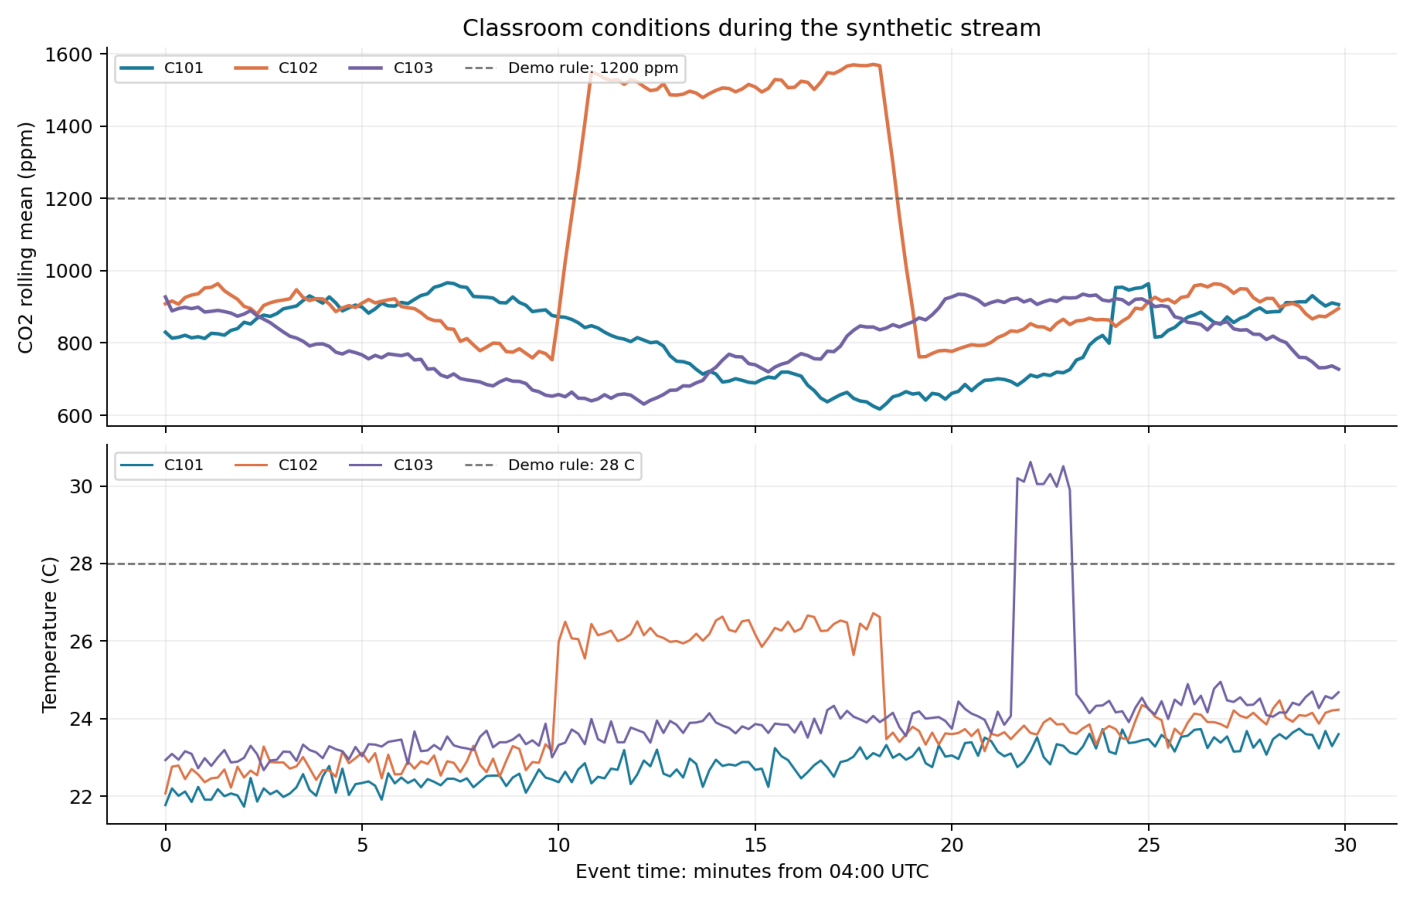

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7.6))
ax.imshow(mpimg.imread(RUN / "stream_results.png"))
ax.axis("off")
plt.tight_layout()
plt.show()

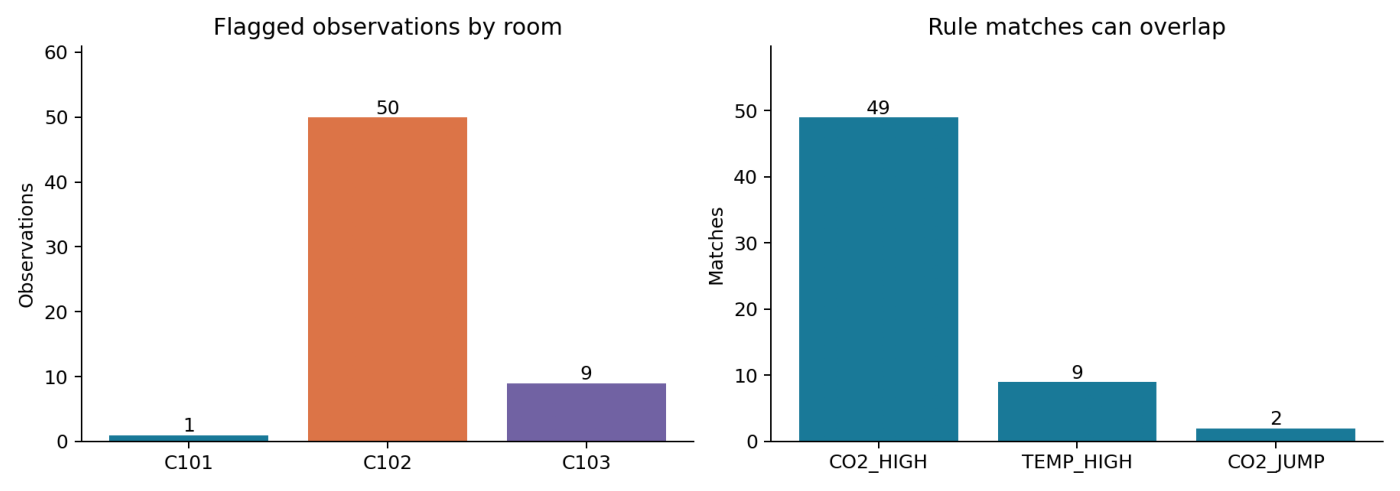

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.imshow(mpimg.imread(RUN / "alert_summary.png"))
ax.axis("off")
plt.tight_layout()
plt.show()

The CO2 jump in C102 is detected at 04:10:00 UTC, but its average CO2 passes 1200 ppm at 04:10:30 UTC. The average reacts later because it still includes earlier, lower readings. The short spike in C101 triggers the jump rule, but its 60-second average stays below 1200 ppm. C103 has nine temperature warnings. Overall, 60 records have warnings; this does not mean there were 60 separate problems.


## 7 Check that the results match
We read the saved raw records again, one line at a time, and process them in the same way. The new results should match the first run. We also calculate the 60-second CO2 averages from the completed table and compare them with the averages calculated during the stream. If all comparisons pass, the next cell prints two PASS messages. More checks are available in the project's `tests` folder.


In [ ]:
REPLAY = WORK / "replayed"
replay_manifest = run_pipeline(input_path=RUN / "raw_stream.jsonl", output=REPLAY, print_every=0)
replayed_metrics = pd.read_csv(REPLAY / "metrics.csv")
pd.testing.assert_frame_equal(metrics, replayed_metrics)

for room, group in metrics.groupby("room"):
    group = group.set_index(pd.to_datetime(group["timestamp"], utc=True))
    batch_mean = group["co2_ppm"].rolling("60s", closed="right", min_periods=1).mean().round(2)
    np.testing.assert_allclose(batch_mean.to_numpy(), group["co2_mean_60s"].to_numpy())

assert manifest["counts"] == replay_manifest["counts"]
print("PASS: replayed metrics match the generated run.")
print("PASS: online rolling means match an independent batch calculation.")

PASS: replayed metrics match the generated run.
PASS: online rolling means match an independent batch calculation.


## 8 Conclusion and limitations
Our program processes records one by one, calculates current indicators, finds unusual conditions and saves the results. The data is generated, so we do not know how well the rules would work with real sensors. Filling missing values can hide short changes, late records are rejected, and the list of used IDs grows during the run. The program also does not reconnect to a network source or restore its processing state after a crash. We could improve it by using real sensors, testing the limits on real data and adding a live dashboard.
